<a href="https://colab.research.google.com/github/ArmanHuang/ArmanHuang/blob/main/Training_Model_Clinical_App.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Setup Environment

In [ ]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
import pandas as pd
import numpy as np

client = bigquery.Client(project="smartgate-a021d")

#Load Data (VALID QUERY)

In [ ]:
query_core = """
SELECT
  p.subject_id,
  p.anchor_age AS age,
  p.gender,
  a.hadm_id,
  a.admittime,
  a.dischtime
FROM `physionet-data.mimiciv_3_1_hosp.patients` p
JOIN `physionet-data.mimiciv_3_1_hosp.admissions` a
  ON p.subject_id = a.subject_id
"""
df = client.query(query_core).to_dataframe()

#Preprocessing Waktu & Sorting

In [ ]:
df['admittime'] = pd.to_datetime(df['admittime'])
df['dischtime'] = pd.to_datetime(df['dischtime'])

df = df.sort_values(['subject_id','admittime'])

df['next_admit'] = df.groupby('subject_id')['admittime'].shift(-1)
df['days_to_next'] = (df['next_admit'] - df['dischtime']).dt.days

df['readmitted'] = (
    (df['days_to_next'] >= 1) &
    (df['days_to_next'] <= 30)
).astype(int)

#JOIN DIAGNOSIS (ICD)

In [ ]:
query_diag = """
SELECT hadm_id, icd_code
FROM `physionet-data.mimiciv_3_1_hosp.diagnoses_icd`
"""
diag = client.query(query_diag).to_dataframe()

# Comorbidity count
comorb = diag.groupby('hadm_id')['icd_code'].nunique().reset_index()
comorb.columns = ['hadm_id','comorbidity_count']

df = df.merge(comorb, on='hadm_id', how='left')
df['comorbidity_count'] = df['comorbidity_count'].fillna(0)

# ICD first character
diag['icd_group'] = diag['icd_code'].str[0]
icd_group = diag.groupby(['hadm_id','icd_group']).size().unstack(fill_value=0)

df = df.merge(icd_group, on='hadm_id', how='left')
df = df.fillna(0)


#LAB FEATURE

In [ ]:
query_lab = """
SELECT
    hadm_id,
    itemid,
    AVG(valuenum) as avg_value
FROM `physionet-data.mimiciv_3_1_hosp.labevents`
WHERE itemid IN (50912,51222,50931)
GROUP BY hadm_id, itemid
"""

lab = client.query(query_lab).to_dataframe()

lab_pivot = lab.pivot(index='hadm_id', columns='itemid', values='avg_value')

rename_dict = {
    50912: 'avg_creatinine',
    51222: 'avg_hemoglobin',
    50931: 'avg_glucose'
}

lab_pivot = lab_pivot.rename(columns=rename_dict)

df = df.merge(lab_pivot, on='hadm_id', how='left')

# Pastikan kolom selalu ada walaupun kosong
for col in ['avg_creatinine', 'avg_hemoglobin', 'avg_glucose']:
    if col not in df.columns:
        df[col] = np.nan

# Isi missing dengan median
df[['avg_creatinine','avg_hemoglobin','avg_glucose']] = \
df[['avg_creatinine','avg_hemoglobin','avg_glucose']].fillna(
    df[['avg_creatinine','avg_hemoglobin','avg_glucose']].median()
)

#MEDICATION COUNT

In [ ]:
query_med = """
SELECT hadm_id, COUNT(DISTINCT drug) as num_medications
FROM `physionet-data.mimiciv_3_1_hosp.prescriptions`
GROUP BY hadm_id
"""
med = client.query(query_med).to_dataframe()

df = df.merge(
    med,
    on='hadm_id',
    how='left',
    suffixes=('','_drop')
)

# Hapus kolom duplikat otomatis
df = df.loc[:, ~df.columns.str.endswith('_drop')]

df['num_medications'] = df['num_medications'].fillna(0)

#Feature Engineering (BASELINE)

In [ ]:

# Basic
df['length_of_stay'] = (df['dischtime'] - df['admittime']).dt.days
df['previous_admissions'] = df.groupby('subject_id').cumcount()

# Interaction
df['los_x_comorb'] = df['length_of_stay'] * df['comorbidity_count']

# =====================================================
# CLINICAL FLAGS (IMPORTANT)
# =====================================================
df['glucose_flag'] = (df['avg_glucose'] > 200).astype(int)
df['creatinine_flag'] = (df['avg_creatinine'] > 2).astype(int)
df['hb_flag'] = (df['avg_hemoglobin'] < 10).astype(int)
df['polypharmacy_flag'] = (df['num_medications'] >= 15).astype(int)

# =====================================================
# SEVERITY FEATURES
# =====================================================
df['creatinine_severe'] = (df['avg_creatinine'] >= 5).astype(int)
df['glucose_severe'] = (df['avg_glucose'] >= 300).astype(int)
df['los_severe'] = (df['length_of_stay'] >= 14).astype(int)
df['comorb_severe'] = (df['comorbidity_count'] >= 8).astype(int)

# =====================================================
# DROP ICD NOISE
# =====================================================
df = df.drop(columns=[col for col in df.columns if len(col) == 1], errors='ignore')

#FINAL FEATURE SET

In [ ]:
X = df.drop(columns=[
    'subject_id','hadm_id','admittime','dischtime',
    'next_admit','days_to_next','readmitted'
])

y = df['readmitted']

# encoding
X = pd.get_dummies(X, columns=['gender'], drop_first=True)
feature_columns = X.columns.tolist()

#Encoding Gender


In [ ]:
if 'gender' in X.columns:
    X = pd.get_dummies(X, columns=['gender'], drop_first=True)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

feature_columns = X.columns.tolist()

#TRAIN TEST SPLIT

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

ratio = (y_train == 0).sum() / (y_train == 1).sum()


#COMPARISON MODEL

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, precision_score, recall_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "XGBoost": XGBClassifier(scale_pos_weight=ratio)
}

results = []

for name, m in models.items():
    m.fit(X_train, y_train)

    y_pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:,1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)
results_df = results_df.round(3)
results_df

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.823,0.503,0.035,0.065,0.669
1,Random Forest,0.821,0.462,0.062,0.109,0.672
2,Gradient Boosting,0.824,0.556,0.026,0.050,0.694
3,XGBoost,0.655,0.283,0.617,0.388,0.694


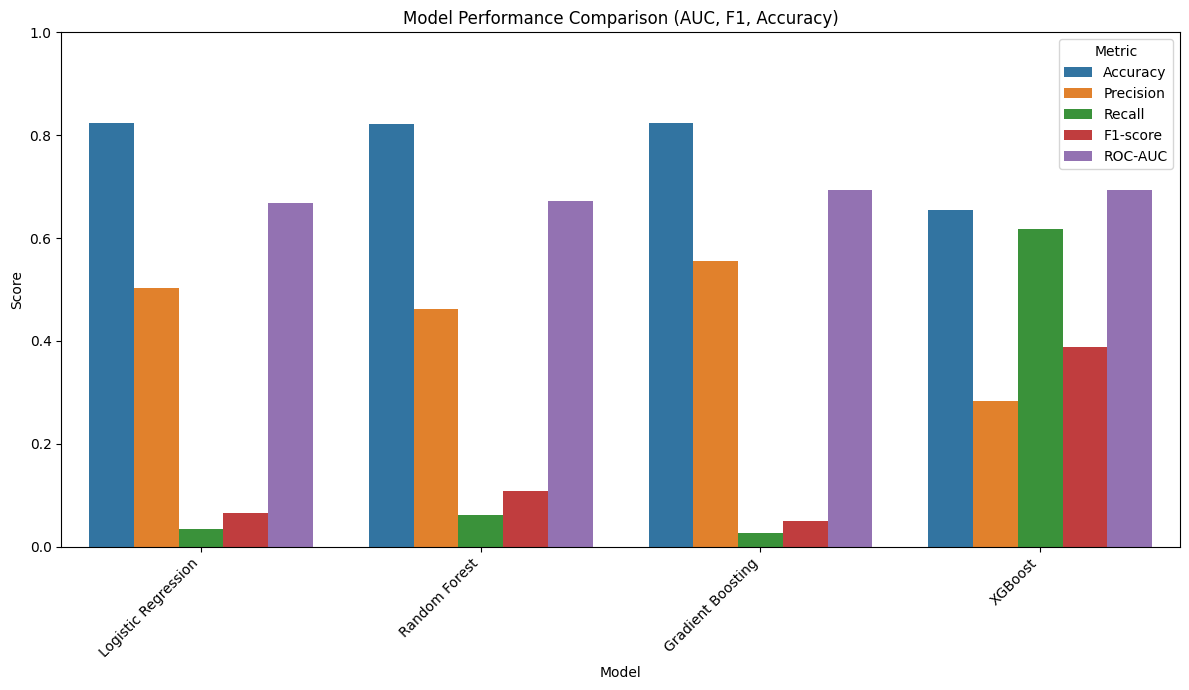

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Melt the DataFrame to easily plot all metrics
results_melted = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 7))
sns.barplot(x='Model', y='Score', hue='Metric', data=results_melted)
plt.title('Model Performance Comparison (AUC, F1, Accuracy)')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0, 1) # Scores are between 0 and 1
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

#MODEL FINAL


In [ ]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

ratio = (y_train == 0).sum() / (y_train == 1).sum()

model = XGBClassifier(
    scale_pos_weight=ratio,
    n_estimators=800,
    max_depth=8,
    learning_rate=0.01,
    subsample=0.6,
    colsample_bytree=1.0,
    random_state=42
)

model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:,1]
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ROC-AUC: 0.6995782022179428


#CONFUSION MATRIX


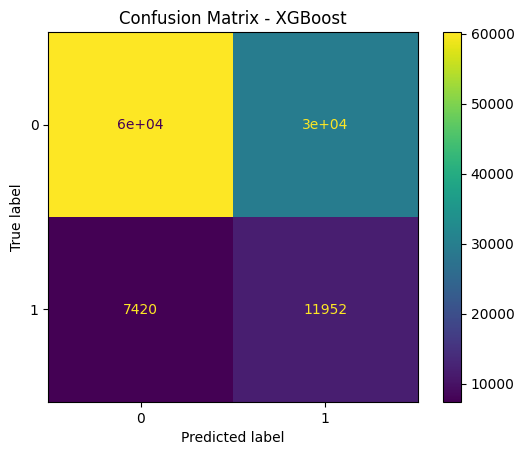

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix - XGBoost")
plt.show()

#ROC CURVE

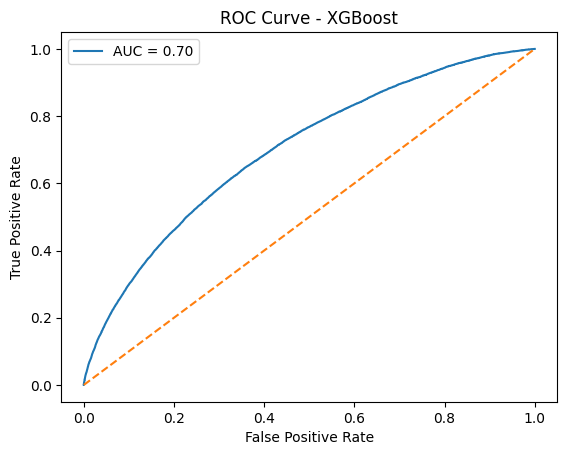

In [ ]:
from sklearn.metrics import roc_curve, auc

y_prob = model.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.89      0.67      0.76     89834
           1       0.29      0.62      0.39     19372

    accuracy                           0.66    109206
   macro avg       0.59      0.64      0.58    109206
weighted avg       0.78      0.66      0.70    109206



# Penjelasan Calssification Report

Model XGBoost menunjukkan performa yang cukup baik dalam mendeteksi pasien dengan risiko readmission, dengan nilai recall sebesar 0.62 pada kelas readmission.

Hal ini menunjukkan bahwa model mampu mengidentifikasi sebagian besar pasien berisiko tinggi, yang sangat penting dalam konteks klinis.

Meskipun nilai precision relatif rendah, pendekatan ini tetap relevan karena dalam sistem kesehatan lebih diutamakan untuk meminimalkan kasus yang terlewat dibandingkan mengurangi false positive

In [ ]:
print("Class imbalance ratio:", ratio)

Class imbalance ratio: 4.637431277908267


Dataset menunjukkan ketidakseimbangan kelas dengan rasio sebesar 4.63, di mana jumlah pasien yang tidak mengalami readmission jauh lebih besar dibandingkan pasien yang mengalami readmission.

Untuk mengatasi hal ini, digunakan parameter scale_pos_weight pada model XGBoost guna meningkatkan kemampuan model dalam mendeteksi kelas minoritas (readmission).

#ROC THRESHOLD

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

youden_index = tpr - fpr
optimal_idx = youden_index.argmax()
optimal_threshold = thresholds[optimal_idx]

high_cutoff = 0.7

print("Optimal Threshold:", optimal_threshold)
print("High Cutoff:", high_cutoff)

Optimal Threshold: 0.48615465
High Cutoff: 0.7


#Explainable AI (SHAP)

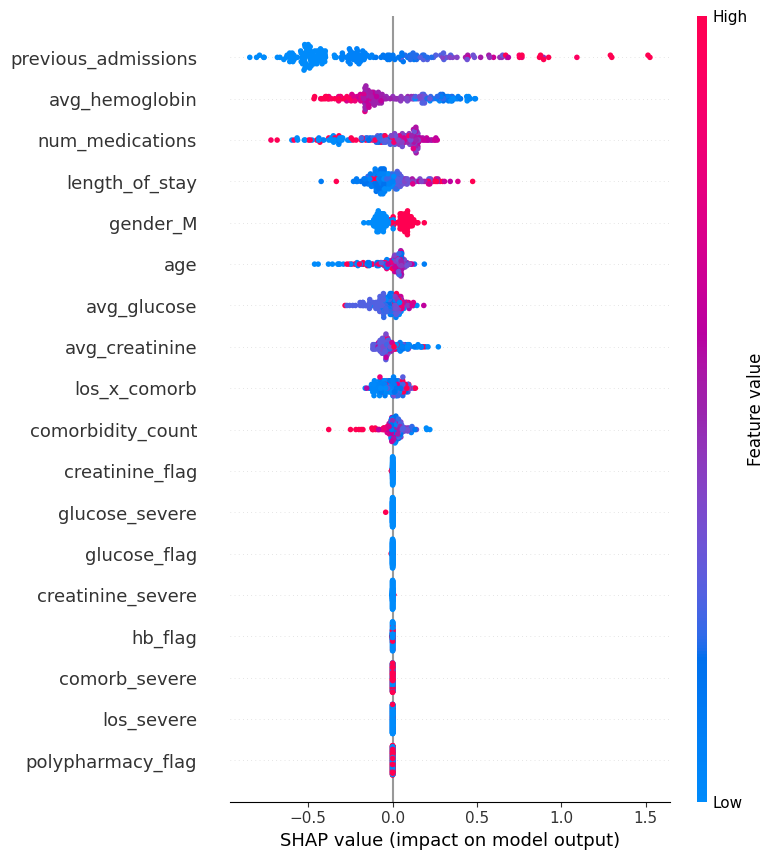

In [ ]:
import shap
import matplotlib.pyplot as plt

# explainer (lebih cepat)
explainer = shap.TreeExplainer(model, approximate=True)

# sampling (biar gak lemot)
X_sample = X_test.sample(200, random_state=42)

# hitung shap
shap_values = explainer.shap_values(X_sample)

# ======================
# HANDLE MULTI-CLASS
# ======================
if isinstance(shap_values, list):
    shap_vals = shap_values[0]
    expected_val = explainer.expected_value[0]
else:
    shap_vals = shap_values
    expected_val = explainer.expected_value

# ======================
# VISUALIZATION
# ======================

# 1. beeswarm
shap.summary_plot(shap_vals, X_sample)


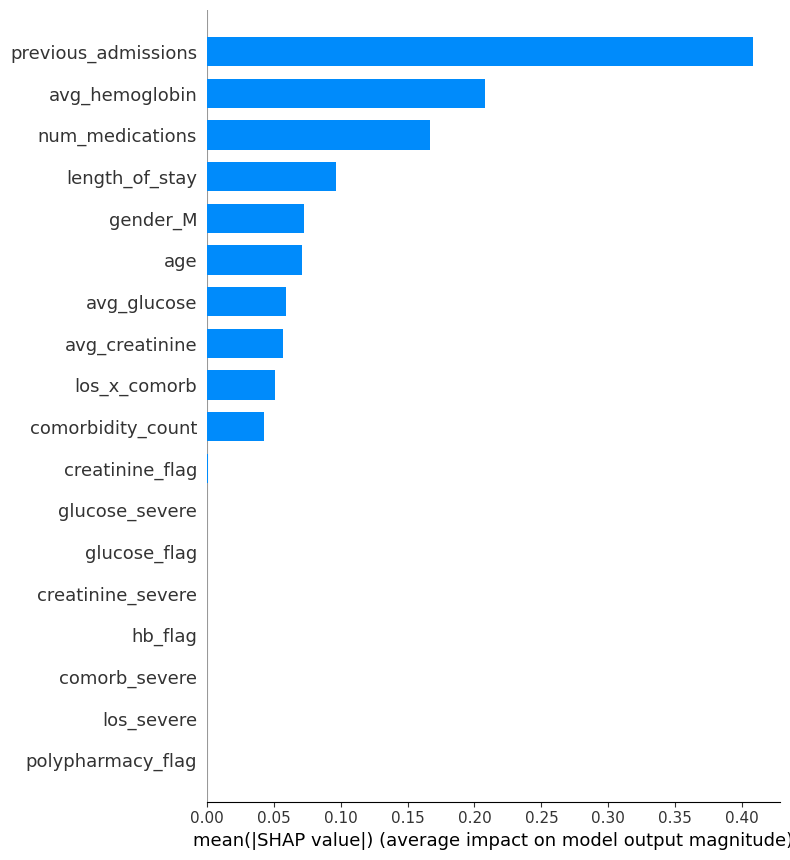

In [ ]:

# 2. bar
shap.summary_plot(shap_vals, X_sample, plot_type="bar")



In [ ]:
# 3. force plot
shap.initjs()
shap.force_plot(
    expected_val,
    shap_vals[0],
    X_sample.iloc[0]
)


In [ ]:
force_plot = shap.force_plot(
    expected_val,
    shap_vals[0],
    X_sample.iloc[0]
)

shap.save_html("force_plot.html", force_plot)

#(Area Under the Precision-Recall Curve)


In [ ]:
from sklearn.metrics import average_precision_score, precision_recall_curve

# probability kelas positif
y_pred_proba = model.predict_proba(X_test)[:, 1]

# hitung AUPRC
auprc = average_precision_score(y_test, y_pred_proba)

print("AUPRC:", auprc)

AUPRC: 0.3449568609717782


In [ ]:
baseline = sum(y_test) / len(y_test)
print("Baseline AUPRC:", baseline)

Baseline AUPRC: 0.17738952072230463


In [ ]:
from sklearn.metrics import roc_auc_score

roc = roc_auc_score(y_test, y_pred_proba)
print("ROC-AUC:", roc)

ROC-AUC: 0.6995782022179428


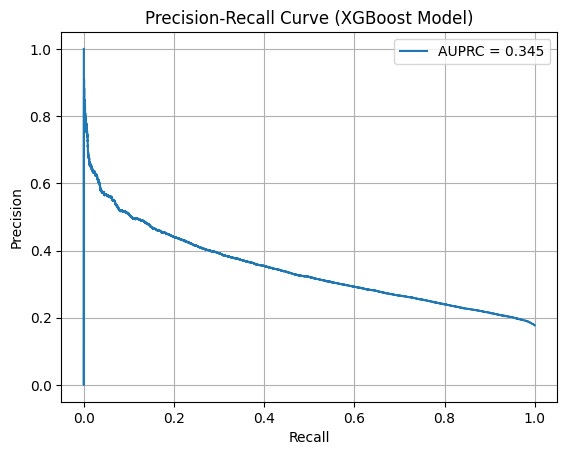

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Probabilitas model
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Hitung PR Curve
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)

# Hitung AUPRC
auprc = average_precision_score(y_test, y_pred_proba)

# Plot
plt.figure()
plt.plot(recall, precision, label=f"AUPRC = {auprc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (XGBoost Model)")
plt.legend()
plt.grid()

plt.show()

In [ ]:
print(models)

{'Logistic Regression': LogisticRegression(max_iter=1000), 'Random Forest': RandomForestClassifier(n_estimators=200), 'Gradient Boosting': GradientBoostingClassifier(), 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)}


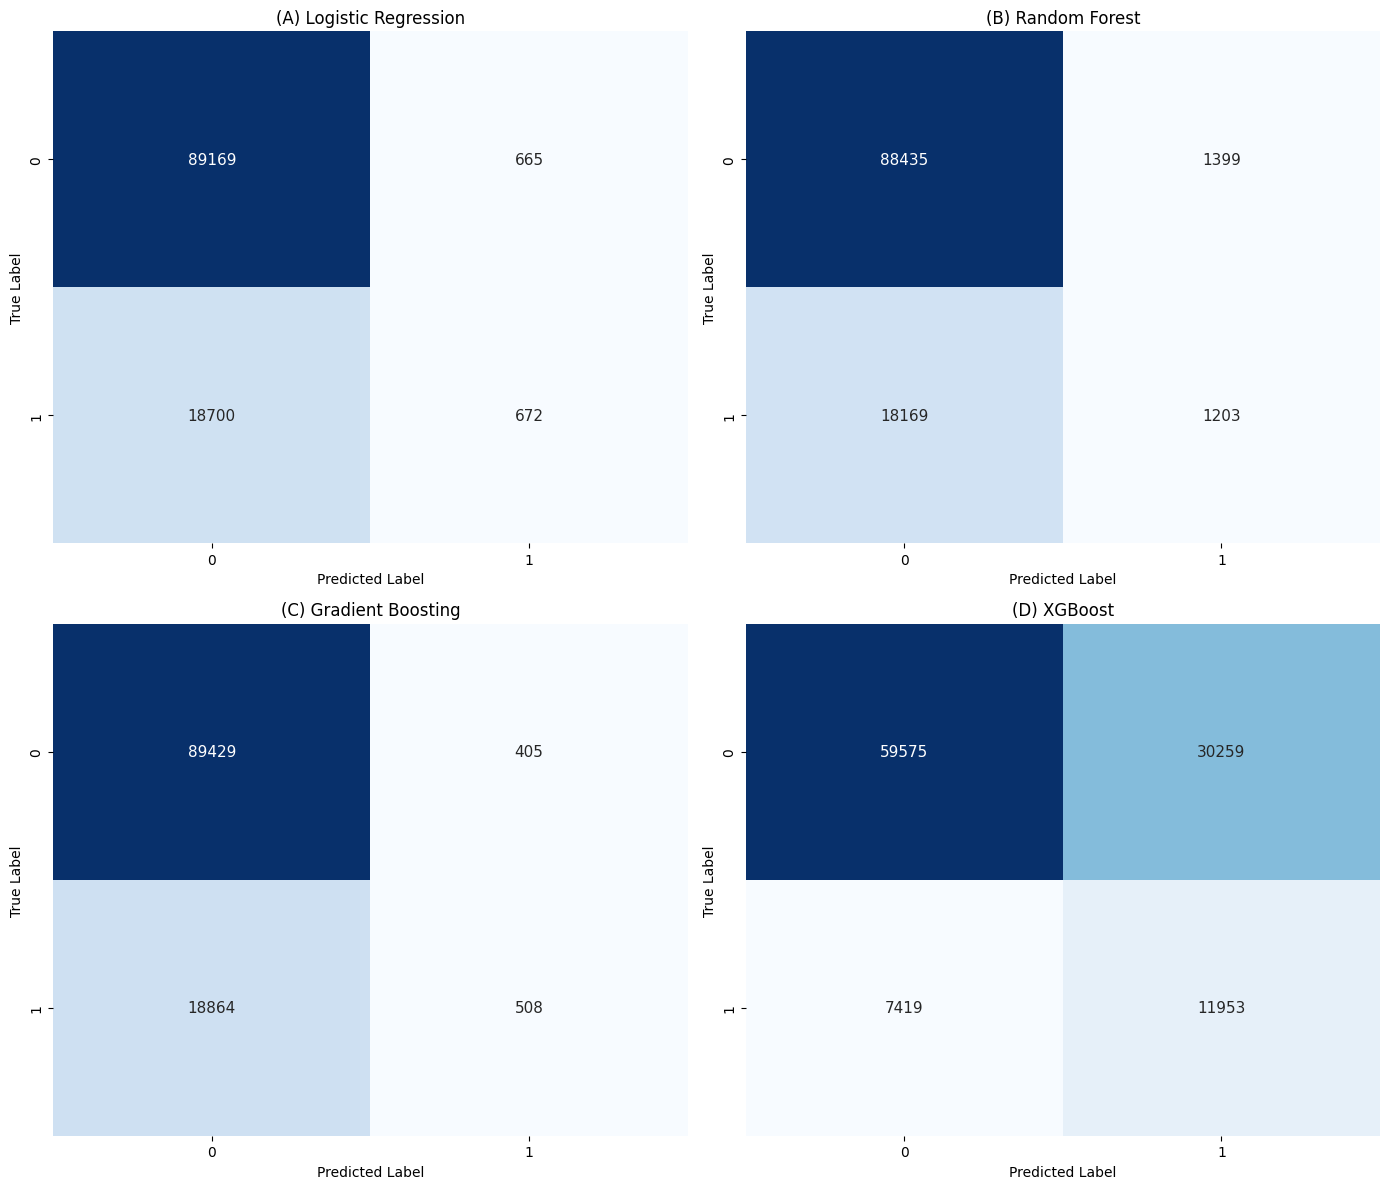

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

titles = [
    "(A) Logistic Regression",
    "(B) Random Forest",
    "(C) Gradient Boosting",
    "(D) XGBoost"
]

for ax, ((name, model), title) in zip(
    axes.flatten(),
    zip(models.items(), titles)
):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=ax,
        annot_kws={"size":11}
    )

    ax.set_title(title, fontsize=12)

    ax.set_xlabel("Predicted Label")

    ax.set_ylabel("True Label")

plt.tight_layout()

plt.savefig(
    "Figure5_ConfusionMatrixComparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

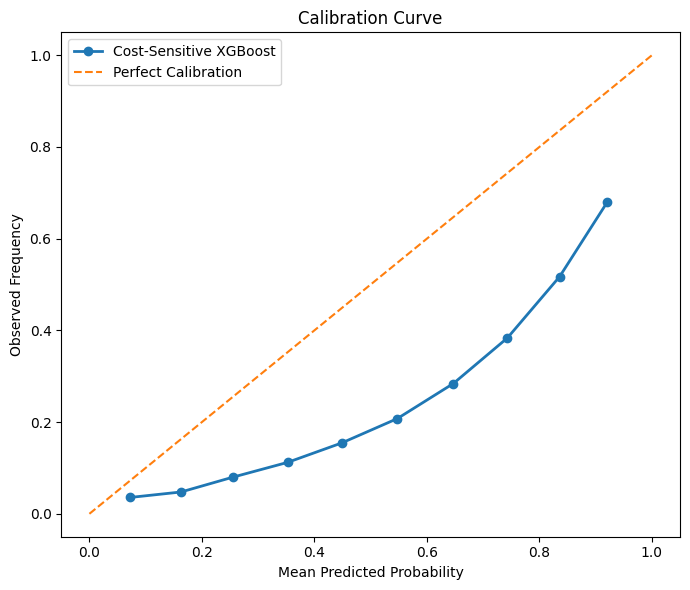

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

xgb_model = models['XGBoost']

y_prob = xgb_model.predict_proba(X_test)[:,1]

prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob,
    n_bins=10
)

plt.figure(figsize=(7,6))

plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    linewidth=2,
    label='Cost-Sensitive XGBoost'
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--',
    label='Perfect Calibration'
)

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Frequency')
plt.title('Calibration Curve')

plt.legend()

plt.tight_layout()

plt.savefig(
    'Calibration_Curve_XGBoost.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

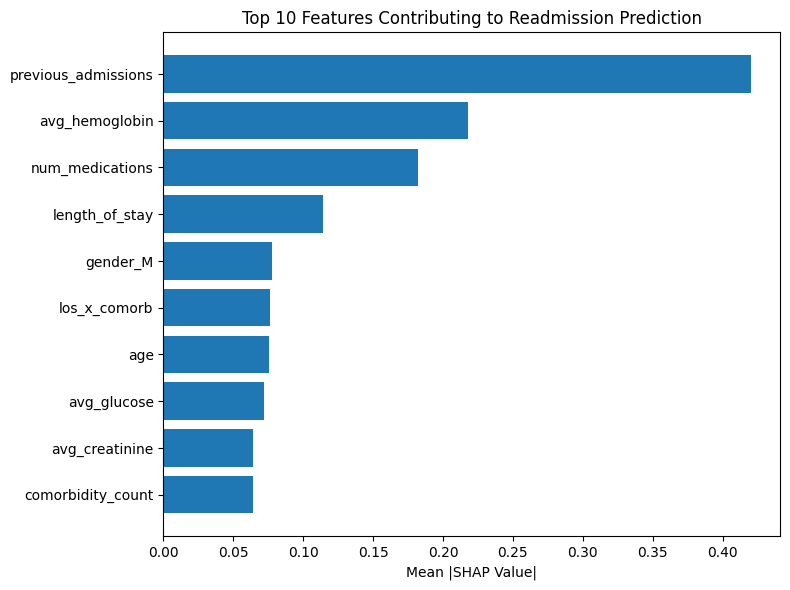

In [ ]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

xgb_model = models['XGBoost']

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test)

importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': abs(shap_values).mean(axis=0)
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(8,6))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.gca().invert_yaxis()

plt.xlabel('Mean |SHAP Value|')

plt.title(
    'Top 10 Features Contributing to Readmission Prediction'
)

plt.tight_layout()

plt.savefig(
    'Top10_SHAP_Features.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

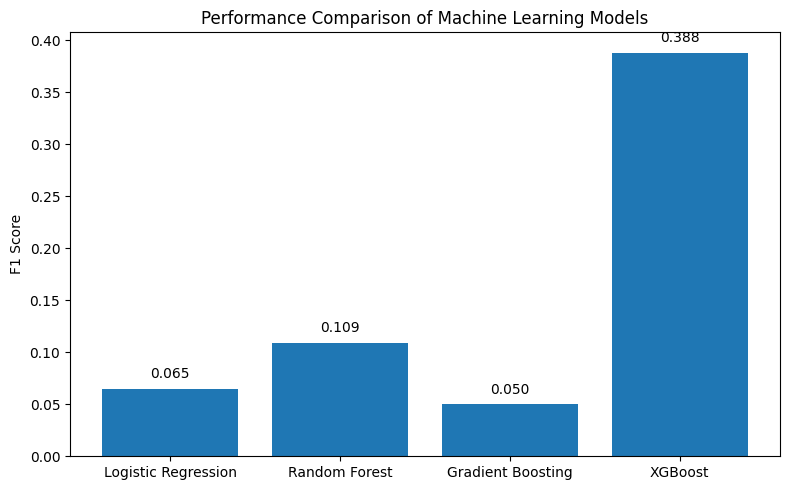

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    results_df['Model'],
    results_df['F1-score']
)

plt.ylabel('F1 Score')

plt.title(
    'Performance Comparison of Machine Learning Models'
)

for i, v in enumerate(results_df['F1-score']):
    plt.text(
        i,
        v + 0.01,
        f'{v:.3f}',
        ha='center'
    )

plt.tight_layout()

plt.savefig(
    'Model_Comparison_F1.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

In [ ]:
results_df.head()

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.823,0.503,0.035,0.065,0.669
1,Random Forest,0.821,0.462,0.062,0.109,0.672
2,Gradient Boosting,0.824,0.556,0.026,0.050,0.694
3,XGBoost,0.655,0.283,0.617,0.388,0.694


#Export Model


In [ ]:
import joblib

joblib.dump(feature_columns, "feature_columns.pkl")
joblib.dump(optimal_threshold, "threshold.pkl")
joblib.dump(high_cutoff, "high_cutoff.pkl")
model.save_model("readmission_model.json")

In [ ]:
print("Max probability in test set:", y_prob.max())
print("Min probability in test set:", y_prob.min())

Max probability in test set: 0.9421392
Min probability in test set: 0.013196872


In [ ]:
print("Optimal Threshold:", optimal_threshold)

Optimal Threshold: 0.48615465
